PART A: SVR kernels on non-linear data
Linear               R^2 = 0.5525   RMSE = 0.5066   support vectors = 125
Polynomial (deg=3)   R^2 = 0.7760   RMSE = 0.3584   support vectors = 120
RBF                  R^2 = 0.9302   RMSE = 0.2001   support vectors = 101


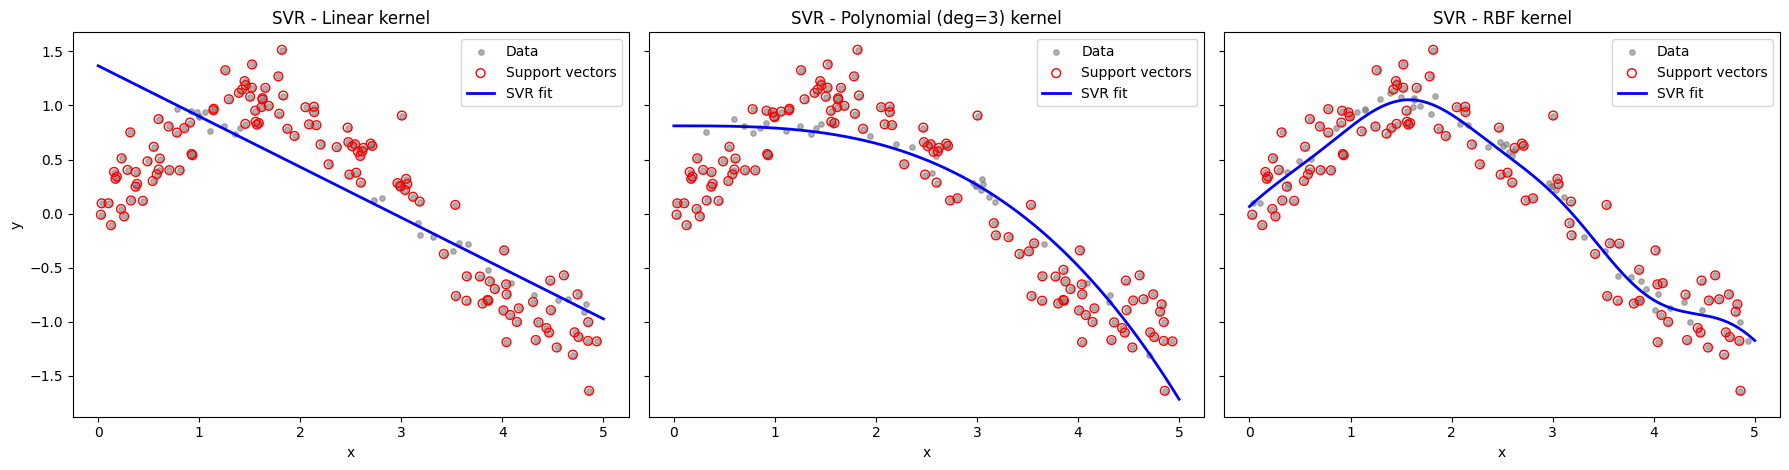


PART B: Effect of hyperparameters


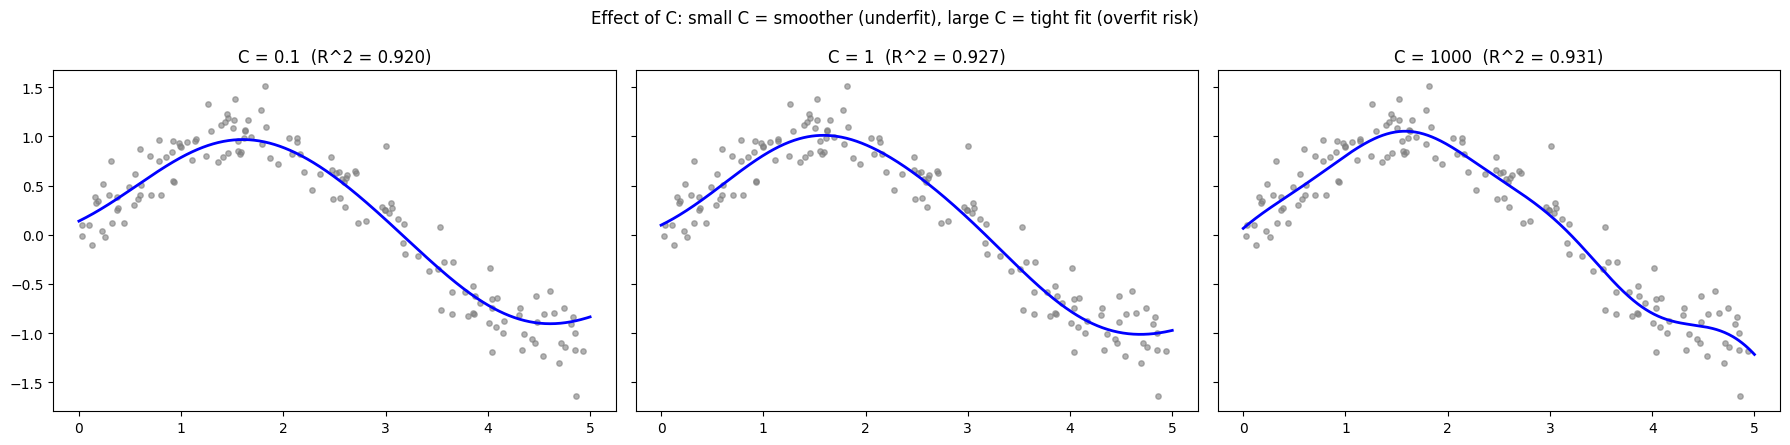

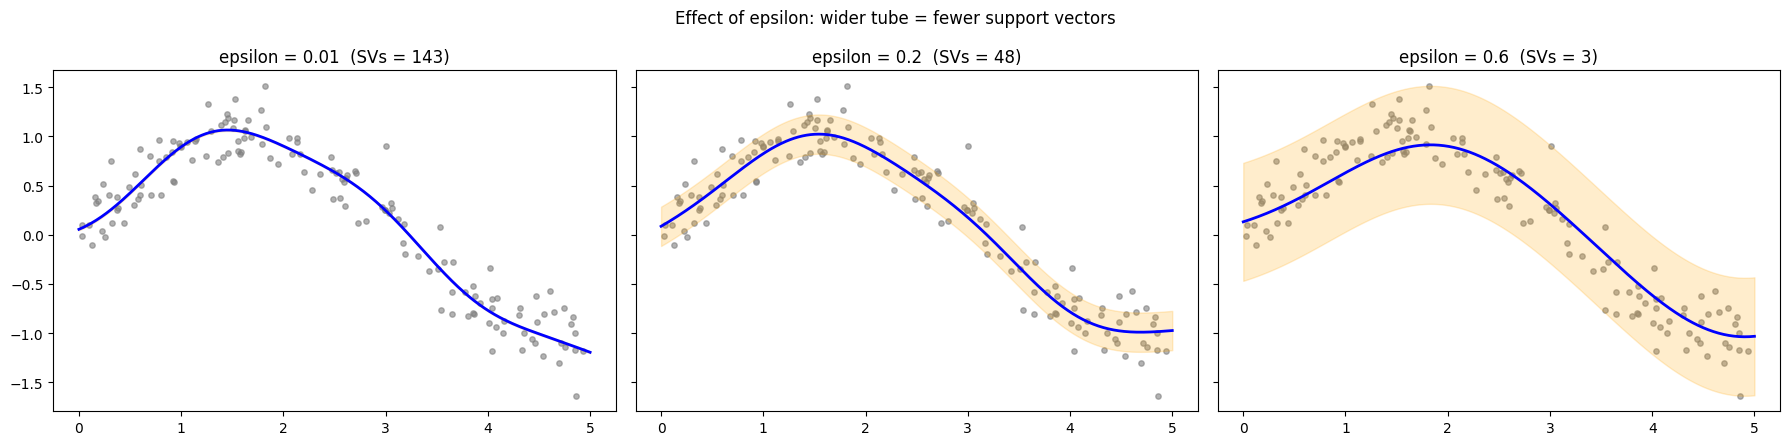

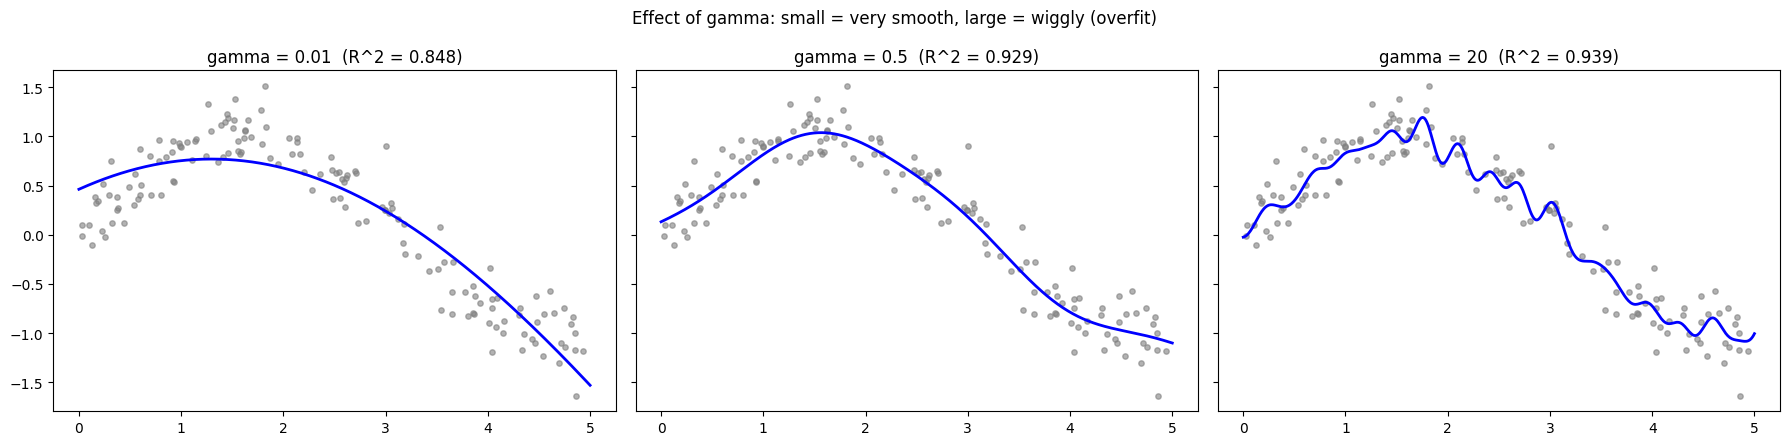


PART C: SVR on the Diabetes dataset
SVR (default RBF)            MAE =  38.924  RMSE =  50.265  R^2 = 0.5231

Best parameters: {'C': 1, 'epsilon': 0.2, 'gamma': 0.01, 'kernel': 'rbf'}
Best CV R^2    : 0.459
SVR (tuned)                  MAE =  41.622  RMSE =  52.231  R^2 = 0.4851

PART D: SVR vs Linear Regression
Linear Regression            MAE =  42.794  RMSE =  53.853  R^2 = 0.4526
SVR (tuned)                  MAE =  41.622  RMSE =  52.231  R^2 = 0.4851


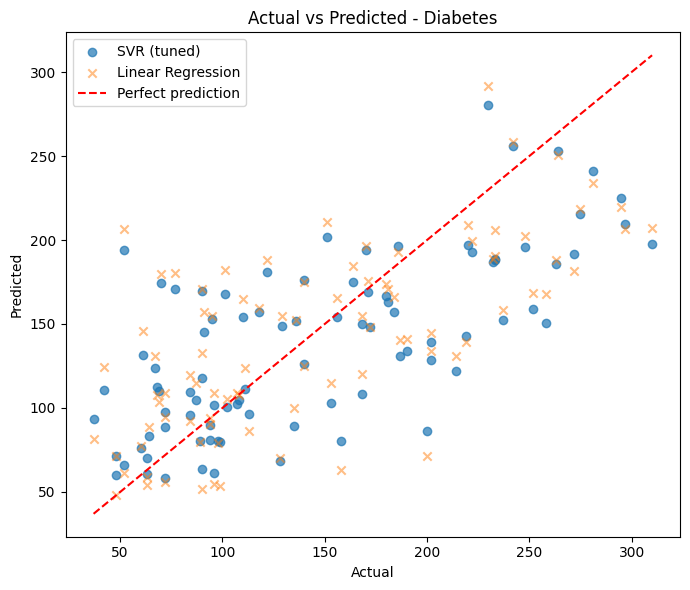


Conclusion: SVR fits a function that keeps most points inside an epsilon-wide tube, penalizing only points outside it. Kernels (RBF, polynomial) let it model non-linear patterns; C, epsilon and gamma control the bias-variance trade-off.


In [ ]:
"""
Assignment 7: Implement SVM Algorithm for Regression (SVR).

Parts:
  A. SVR on non-linear synthetic data: linear vs polynomial vs RBF kernels
  B. Effect of hyperparameters C, epsilon and gamma
  C. Support vectors and the epsilon-tube
  D. SVR on a real dataset (Diabetes) with scaling + GridSearchCV
  E. Comparison with Linear Regression

Install: pip install numpy pandas matplotlib seaborn scikit-learn
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

np.random.seed(42)

# ==================================================================
# PART A: Different kernels on non-linear data
# ==================================================================
print("=" * 60)
print("PART A: SVR kernels on non-linear data")
print("=" * 60)

X = np.sort(5 * np.random.rand(150, 1), axis=0)
y = np.sin(X).ravel() + 0.2 * np.random.randn(150)     # noisy sine wave
X_plot = np.linspace(0, 5, 500).reshape(-1, 1)

kernels = {
    "Linear": SVR(kernel="linear", C=100, epsilon=0.1),
    "Polynomial (deg=3)": SVR(kernel="poly", degree=3, C=100, epsilon=0.1, gamma="scale"),
    "RBF": SVR(kernel="rbf", C=100, gamma=0.5, epsilon=0.1),
}

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for ax, (name, model) in zip(axes, kernels.items()):
    model.fit(X, y)
    pred = model.predict(X)
    print(f"{name:<20} R^2 = {r2_score(y, pred):.4f}   "
          f"RMSE = {np.sqrt(mean_squared_error(y, pred)):.4f}   "
          f"support vectors = {len(model.support_)}")

    ax.scatter(X, y, s=15, color="gray", alpha=0.6, label="Data")
    ax.scatter(X[model.support_], y[model.support_], s=40,
               facecolors="none", edgecolors="red", label="Support vectors")
    ax.plot(X_plot, model.predict(X_plot), color="blue", linewidth=2, label="SVR fit")
    ax.set_title(f"SVR - {name} kernel")
    ax.set_xlabel("x")
    ax.legend()
axes[0].set_ylabel("y")
plt.tight_layout()
plt.show()

# ==================================================================
# PART B: Effect of C, epsilon and gamma
# ==================================================================
print("\n" + "=" * 60)
print("PART B: Effect of hyperparameters")
print("=" * 60)

# --- Effect of C (regularization strength) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, C in zip(axes, [0.1, 1, 1000]):
    m = SVR(kernel="rbf", C=C, gamma=0.5, epsilon=0.1).fit(X, y)
    ax.scatter(X, y, s=15, color="gray", alpha=0.6)
    ax.plot(X_plot, m.predict(X_plot), color="blue", linewidth=2)
    ax.set_title(f"C = {C}  (R^2 = {m.score(X, y):.3f})")
plt.suptitle("Effect of C: small C = smoother (underfit), large C = tight fit (overfit risk)")
plt.tight_layout()
plt.show()

# --- Effect of epsilon (width of the tube) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, eps in zip(axes, [0.01, 0.2, 0.6]):
    m = SVR(kernel="rbf", C=10, gamma=0.5, epsilon=eps).fit(X, y)
    ax.scatter(X, y, s=15, color="gray", alpha=0.6)
    line = m.predict(X_plot)
    ax.plot(X_plot, line, color="blue", linewidth=2)
    ax.fill_between(X_plot.ravel(), line - eps, line + eps, alpha=0.2, color="orange")
    ax.set_title(f"epsilon = {eps}  (SVs = {len(m.support_)})")
plt.suptitle("Effect of epsilon: wider tube = fewer support vectors")
plt.tight_layout()
plt.show()

# --- Effect of gamma (RBF reach) ---
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5), sharey=True)
for ax, g in zip(axes, [0.01, 0.5, 20]):
    m = SVR(kernel="rbf", C=10, gamma=g, epsilon=0.1).fit(X, y)
    ax.scatter(X, y, s=15, color="gray", alpha=0.6)
    ax.plot(X_plot, m.predict(X_plot), color="blue", linewidth=2)
    ax.set_title(f"gamma = {g}  (R^2 = {m.score(X, y):.3f})")
plt.suptitle("Effect of gamma: small = very smooth, large = wiggly (overfit)")
plt.tight_layout()
plt.show()

# ==================================================================
# PART C: SVR on real data (Diabetes) with scaling + GridSearchCV
# ==================================================================
print("\n" + "=" * 60)
print("PART C: SVR on the Diabetes dataset")
print("=" * 60)

data = load_diabetes(as_frame=True)
X_d = data.data
y_d = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X_d, y_d, test_size=0.2, random_state=42)

# Scale both X and y (SVR is sensitive to scale)
x_scaler = StandardScaler().fit(X_train)
y_scaler = StandardScaler().fit(y_train.values.reshape(-1, 1))

X_train_s = x_scaler.transform(X_train)
X_test_s = x_scaler.transform(X_test)
y_train_s = y_scaler.transform(y_train.values.reshape(-1, 1)).ravel()


def evaluate(name, model_pred_scaled=None, preds=None):
    """Print regression metrics on the test set in the original units."""
    if preds is None:
        preds = y_scaler.inverse_transform(model_pred_scaled.reshape(-1, 1)).ravel()
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    print(f"{name:<28} MAE = {mae:7.3f}  RMSE = {rmse:7.3f}  R^2 = {r2:.4f}")
    return preds


# Default SVR
svr_default = SVR(kernel="rbf").fit(X_train_s, y_train_s)
evaluate("SVR (default RBF)", svr_default.predict(X_test_s))

# Hyperparameter tuning
param_grid = {
    "kernel": ["linear", "rbf"],
    "C": [0.1, 1, 10, 100],
    "epsilon": [0.01, 0.1, 0.2, 0.5],
    "gamma": ["scale", 0.01, 0.1],
}
grid = GridSearchCV(SVR(), param_grid, cv=5, scoring="r2", n_jobs=-1)
grid.fit(X_train_s, y_train_s)

print("\nBest parameters:", grid.best_params_)
print("Best CV R^2    :", round(grid.best_score_, 4))

best_svr = grid.best_estimator_
svr_pred = evaluate("SVR (tuned)", best_svr.predict(X_test_s))

# ==================================================================
# PART D: Compare with Linear Regression
# ==================================================================
print("\n" + "=" * 60)
print("PART D: SVR vs Linear Regression")
print("=" * 60)

lin = LinearRegression().fit(X_train, y_train)
lin_pred = evaluate("Linear Regression", preds=lin.predict(X_test))
evaluate("SVR (tuned)", preds=svr_pred)

plt.figure(figsize=(7, 6))
plt.scatter(y_test, svr_pred, alpha=0.7, label="SVR (tuned)")
plt.scatter(y_test, lin_pred, alpha=0.5, marker="x", label="Linear Regression")
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Actual vs Predicted - Diabetes")
plt.legend()
plt.tight_layout()
plt.show()

print("\nConclusion: SVR fits a function that keeps most points inside an "
      "epsilon-wide tube, penalizing only points outside it. Kernels (RBF, "
      "polynomial) let it model non-linear patterns; C, epsilon and gamma "
      "control the bias-variance trade-off.")